In [1]:
import numpy as np
from skimage.measure import marching_cubes
import pyvista as pv


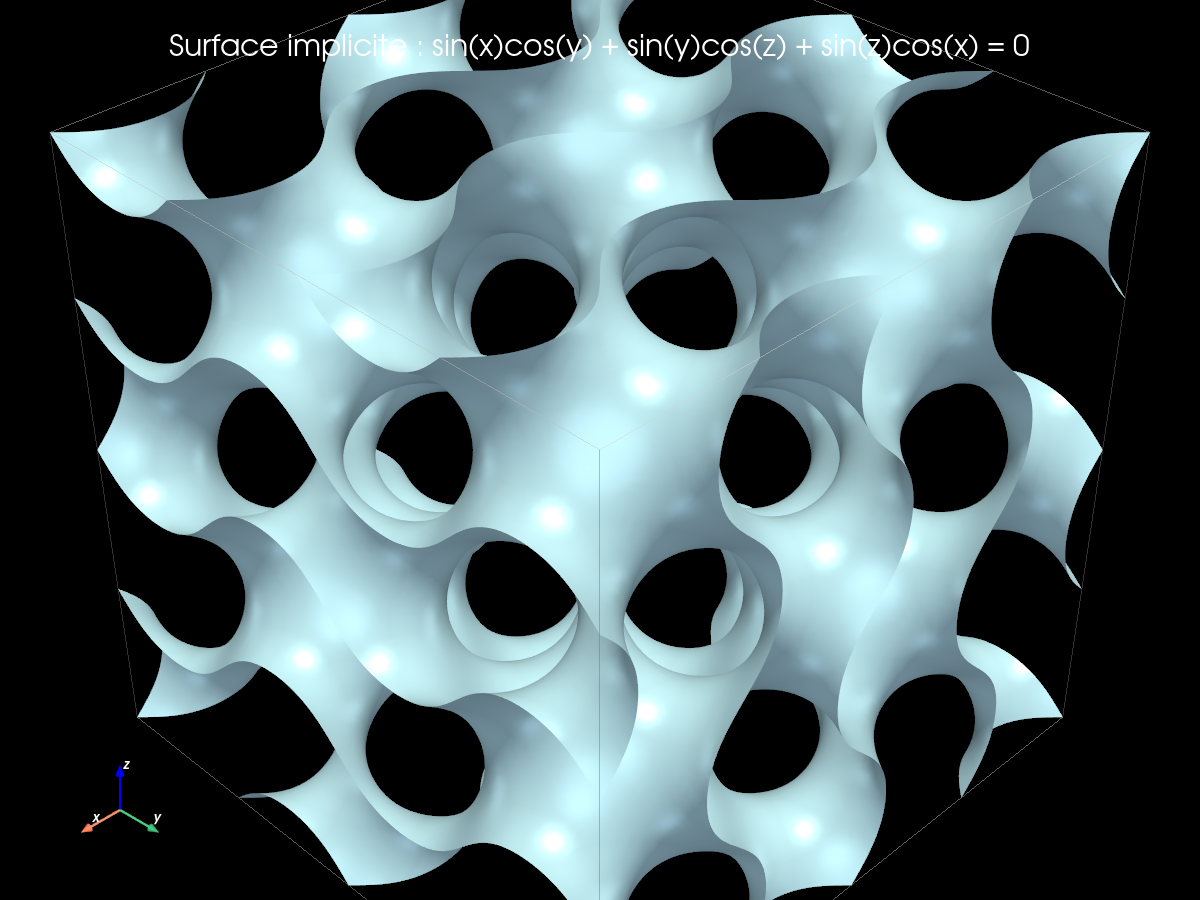

In [2]:
# ============================================================
# Surface implicite :
# sin(x) cos(y) + sin(y) cos(z) + sin(z) cos(x) = 0
# ============================================================

# Domaine 3D
n = 120
xmin, xmax = -2*np.pi, 2*np.pi
ymin, ymax = -2*np.pi, 2*np.pi
zmin, zmax = -2*np.pi, 2*np.pi

x = np.linspace(xmin, xmax, n)
y = np.linspace(ymin, ymax, n)
z = np.linspace(zmin, zmax, n)

dx = x[1] - x[0]
dy = y[1] - y[0]
dz = z[1] - z[0]

X, Y, Z = np.meshgrid(x, y, z, indexing="ij")

# Fonction implicite
F = (
      np.sin(X) * np.cos(Y)
    + np.sin(Y) * np.cos(Z)
    + np.sin(Z) * np.cos(X)
)

# Extraction de l'isosurface f=0 par marching cubes
verts, faces, normals, values = marching_cubes(
    F,
    level=0.0,
    spacing=(dx, dy, dz)
)

# Correction du décalage dû au spacing
verts[:, 0] += xmin
verts[:, 1] += ymin
verts[:, 2] += zmin

# Format des faces pour PyVista :
# chaque triangle doit être écrit [3, i, j, k]
faces_pv = np.hstack([
    np.full((faces.shape[0], 1), 3),
    faces
]).astype(np.int64)

mesh = pv.PolyData(verts, faces_pv)

# Calcul des normales pour un rendu plus lisse
mesh = mesh.compute_normals(
    point_normals=True,
    cell_normals=True,
    auto_orient_normals=True
)

# Optionnel : lissage léger
mesh_smooth = mesh.smooth(
    n_iter=30,
    relaxation_factor=0.05,
    feature_smoothing=False,
    boundary_smoothing=True
)

# ============================================================
# Visualisation PyVista
# ============================================================

plotter = pv.Plotter(window_size=(1200, 900))

plotter.set_background("black")

plotter.add_mesh(
    mesh_smooth,
    color="lightblue",
    smooth_shading=True,
    specular=0.6,
    specular_power=25,
    ambient=0.25,
    show_edges=False
)

# Boîte du domaine
box = pv.Box(bounds=(xmin, xmax, ymin, ymax, zmin, zmax))
plotter.add_mesh(
    box,
    style="wireframe",
    color="white",
    opacity=0.25
)

# Axes
plotter.add_axes(
    xlabel="x",
    ylabel="y",
    zlabel="z",
    line_width=2,
    color="white"
)

plotter.add_title(
    "Surface implicite : sin(x)cos(y) + sin(y)cos(z) + sin(z)cos(x) = 0",
    font_size=12,
    color="white"
)

# Caméra
plotter.camera_position = "iso"
plotter.camera.zoom(1.4)

plotter.show(jupyter_backend='static')